# COMP4318/5318 Assignment 2: Image Classification

### Group number: 217  , SID1: STUDENT_ID_REDACTED , SID2: ..., SID3: ..., SID4: ...

This template notebook includes code to load the  dataset and a skeleton for the main sections that should be included in the notebook. Please stick to this struture for your submitted notebook.

Please focus on making your code clear, with appropriate variable names and whitespace. Include comments and markdown text to aid the readability of your code where relevant. See the specification and marking criteria in the associated specification to guide you when completing your implementation.

## Setup and dependencies
Please use this section to list and set up all your required libraries/dependencies and your plotting environment.

In [4]:
# Import libraries for data handling, visualisation, splitting, and evaluation
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

# Set a fixed random seed so that the validation split and experiments are reproducible
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Use a consistent plotting style throughout the notebook
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Data loading, exploration, and preprocessing

Code to load the dataset is provided in the following cell. Please proceed with your data exploration and preprocessing in the remainder of this section.

In [5]:
# Load the dataset training and test sets as numpy arrays
# assuming Assignment2Data folder is present in the same directory
# as the notebook
X_train = np.load('Assignment2Data/X_train.npy')
y_train = np.load('Assignment2Data/y_train.npy')
X_test = np.load('Assignment2Data/X_test.npy')
y_test = np.load('Assignment2Data/y_test.npy')

### 1.1 Data validation and summary

Before preprocessing, we verify the relationship between the images and labels, inspect the array shapes and data types, and confirm the expected image and class structure. These checks detect path, shape, or label errors before any model is trained.

In [6]:
# Keep explicit references to the unmodified uint8 arrays
X_train_raw = X_train
y_train_raw = y_train
X_test_raw = X_test
y_test_raw = y_test

# Validate that each image has exactly one corresponding label
assert X_train_raw.shape[0] == y_train_raw.shape[0], "Training images and labels do not match."
assert X_test_raw.shape[0] == y_test_raw.shape[0], "Test images and labels do not match."

# Validate the expected 28 x 28 RGB image format and integer labels

assert X_train_raw.shape[1:] == (28, 28, 3), "Unexpected training image shape."
assert X_test_raw.shape[1:] == (28, 28, 3), "Unexpected test image shape."
assert y_train_raw.ndim == 1 and y_test_raw.ndim == 1, "Labels must be one-dimensional."

train_classes = np.unique(y_train_raw)
test_classes = np.unique(y_test_raw)

# The supplied training and test sets should contain the same nine classes
assert np.array_equal(train_classes, test_classes), "Training and test classes do not match."
assert np.array_equal(train_classes, np.arange(9)), "Expected class labels 0 to 8."

dataset_summary = pd.DataFrame(
    {
        "Split": ["Training", "Test"],
        "Samples": [len(X_train_raw), len(X_test_raw)],
        "Image shape": [str(X_train_raw.shape[1:]), str(X_test_raw.shape[1:])],
        "Image dtype": [str(X_train_raw.dtype), str(X_test_raw.dtype)],
        "Pixel minimum": [X_train_raw.min(), X_test_raw.min()],
        "Pixel maximum": [X_train_raw.max(), X_test_raw.max()],
        "Number of classes": [len(train_classes), len(test_classes)],
    }
)

display(dataset_summary)
print("Class labels:", train_classes)
print("Dataset validation completed successfully.")

,Split,Samples,Image shape,Image dtype,Pixel minimum,Pixel maximum,Number of classes
0,Training,32000,"(28, 28, 3)",uint8,0,255,9
1,Test,8000,"(28, 28, 3)",uint8,0,255,9


Class labels: [0 1 2 3 4 5 6 7 8]
Dataset validation completed successfully.


### 1.2 Class distribution

Class counts and proportions are inspected separately for the supplied training and test sets. This identifies class imbalance and checks whether accuracy alone will be sufficient for evaluation. The supplied test set is inspected descriptively here but is not used to choose preprocessing settings, architectures, or hyperparameters.

,Split,Class ID,Class name,Count,Proportion
0,Training,0,Adipose,3490,0.109063
1,Training,1,Background,3431,0.107219
2,Training,2,Debris,3505,0.109531
3,Training,3,Lymphocytes,3656,0.114250
4,Training,4,Mucus,2950,0.092188
5,Training,5,Smooth muscle,4290,0.134063
6,Training,6,Normal colon mucosa,2728,0.085250
7,Training,7,Cancer-associated stroma,3253,0.101656
8,Training,8,Colorectal adenocarcinoma epithelium,4697,0.146781
9,Test,0,Adipose,873,0.109125


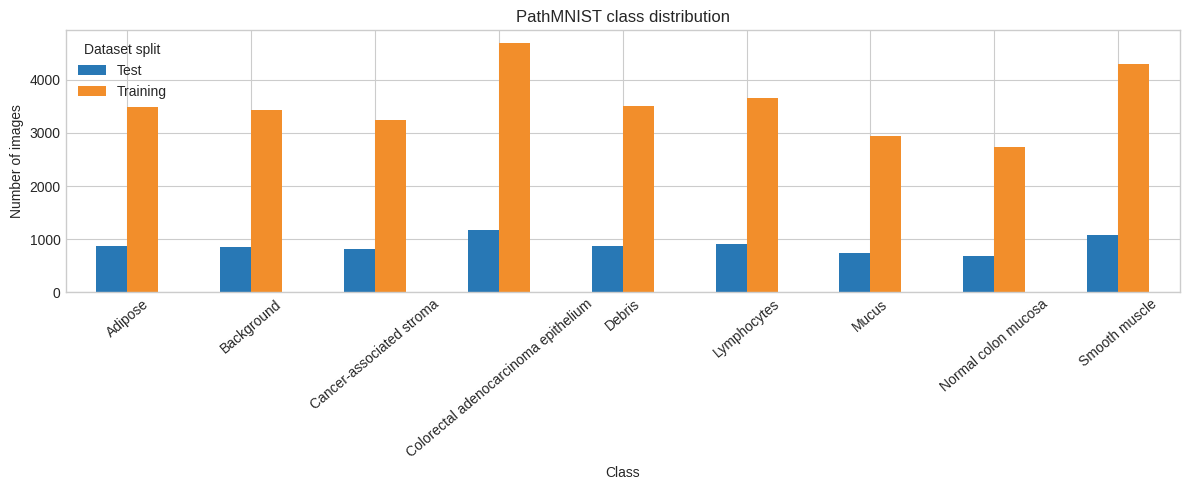

In [7]:
# PathMNIST class names corresponding to labels 0-8
CLASS_NAMES = {
    0: "Adipose",
    1: "Background",
    2: "Debris",
    3: "Lymphocytes",
    4: "Mucus",
    5: "Smooth muscle",
    6: "Normal colon mucosa",
    7: "Cancer-associated stroma",
    8: "Colorectal adenocarcinoma epithelium",
}

def build_class_distribution(labels, split_name):
    # Return class counts and proportions for one dataset split.
    class_ids, counts = np.unique(labels, return_counts=True)
    return pd.DataFrame(
        {
            "Split": split_name,
            "Class ID": class_ids,
            "Class name": [CLASS_NAMES[class_id] for class_id in class_ids],
            "Count": counts,
            "Proportion": counts / len(labels),
        }
    )

class_distribution = pd.concat(
    [
        build_class_distribution(y_train_raw, "Training"),
        build_class_distribution(y_test_raw, "Test"),
    ],
    ignore_index=True,
)

display(class_distribution)

# Plot training and test counts side by side for an immediate imbalance check
distribution_pivot = class_distribution.pivot(
    index="Class name", columns="Split", values="Count"
)
ax = distribution_pivot.plot(kind="bar", figsize=(12, 5), color=["#2878B5", "#F28E2B"])
ax.set_title("PathMNIST class distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=40)
ax.legend(title="Dataset split")
plt.tight_layout()
plt.show()

### 1.3 Visual exploration of the images

One reproducibly selected image from each class is displayed to inspect colour, texture, centring, and visual similarities between tissue categories. Mean images are also shown to reveal class-level colour and structural tendencies that may not be obvious from individual samples.

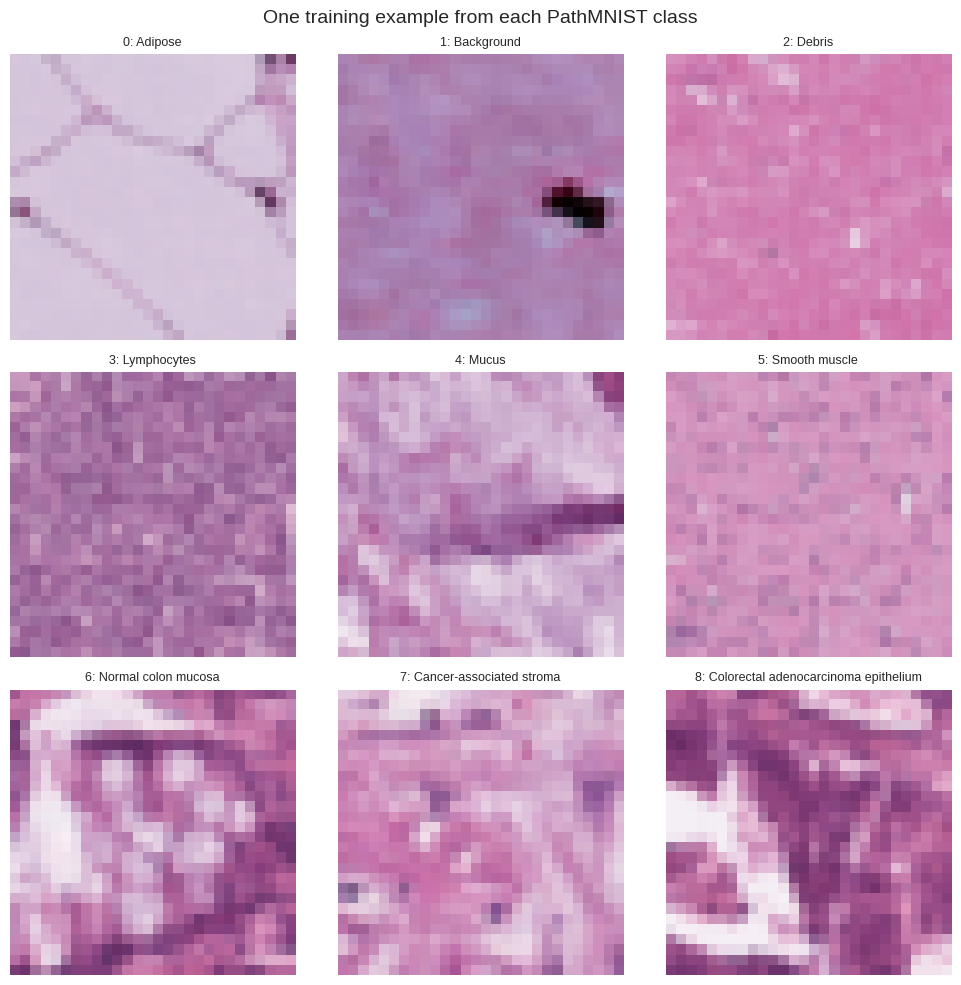

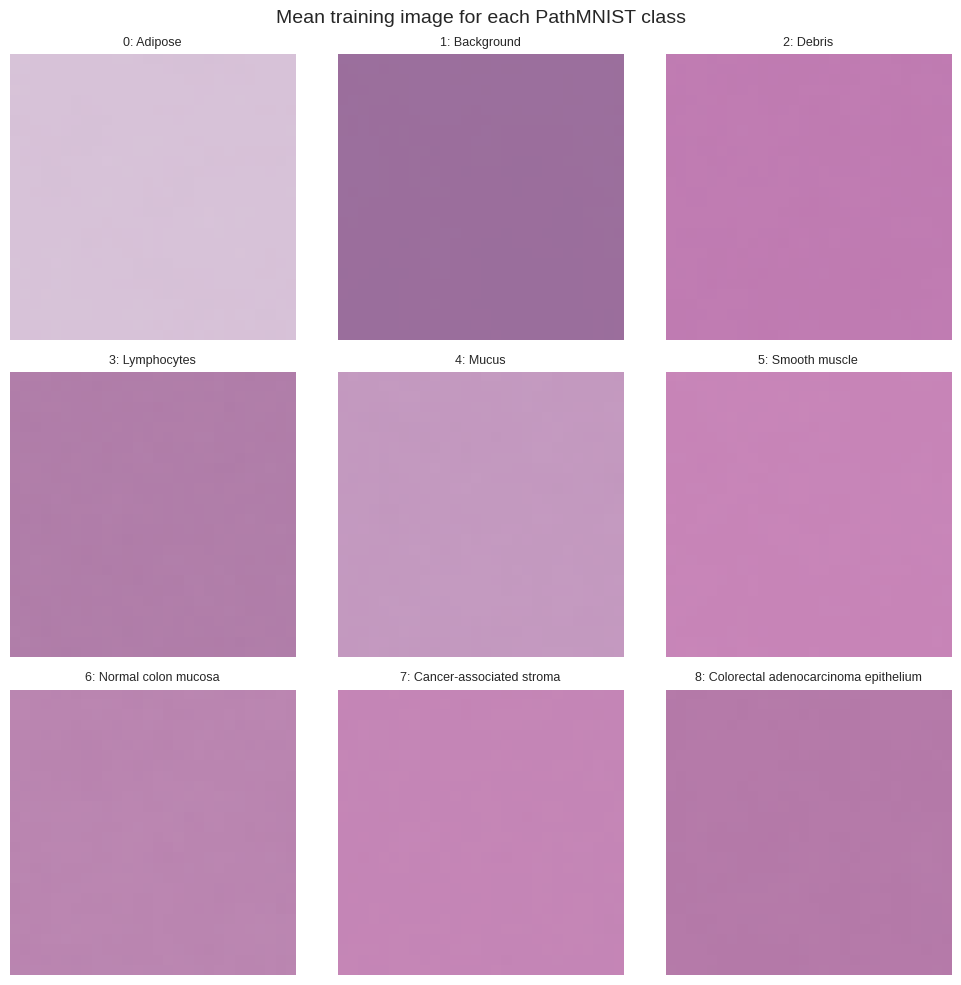

In [8]:
# Use a dedicated generator so image selection is reproducible without changing other experiments
sample_rng = np.random.default_rng(RANDOM_STATE)

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for class_id, ax in zip(train_classes, axes.flat):
    class_indices = np.flatnonzero(y_train_raw == class_id)
    sample_index = sample_rng.choice(class_indices)
    ax.imshow(X_train_raw[sample_index])
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")

fig.suptitle("One training example from each PathMNIST class", fontsize=14)
plt.tight_layout()
plt.show()

# Average all images within each class to expose broad colour and structural patterns
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for class_id, ax in zip(train_classes, axes.flat):
    mean_image = X_train_raw[y_train_raw == class_id].mean(axis=0).astype(np.uint8)
    ax.imshow(mean_image)
    ax.set_title(f"{class_id}: {CLASS_NAMES[class_id]}", fontsize=9)
    ax.axis("off")

fig.suptitle("Mean training image for each PathMNIST class", fontsize=14)
plt.tight_layout()
plt.show()

### 1.4 Pixel-intensity exploration

Global and channel-wise statistics are calculated to determine the numeric scale and colour characteristics of the images. A subsample is used for the histogram to keep plotting efficient while retaining a representative view of the intensity distribution.

,Channel,Mean,Standard deviation,Minimum,Maximum
0,Red,188.65,31.91,0,255
1,Green,135.93,45.60,0,252
2,Blue,180.05,32.18,0,255


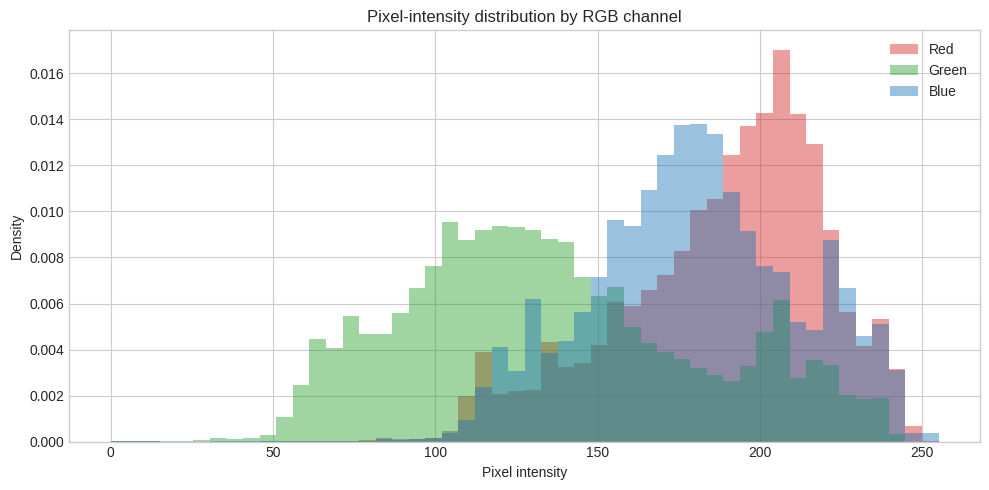

,Class ID,Class name,Mean intensity,Intensity standard deviation
0,0,Adipose,208.67,26.35
1,1,Background,140.97,55.89
2,2,Debris,164.57,41.09
3,3,Lymphocytes,157.37,36.42
4,4,Mucus,180.28,34.59
5,5,Smooth muscle,172.24,40.23
6,6,Normal colon mucosa,165.66,41.93
7,7,Cancer-associated stroma,171.08,34.98
8,8,Colorectal adenocarcinoma epithelium,157.46,41.72


In [9]:
# Compute channel statistics across all training images and spatial positions
channel_names = ["Red", "Green", "Blue"]
channel_statistics = pd.DataFrame(
    {
        "Channel": channel_names,
        "Mean": X_train_raw.mean(axis=(0, 1, 2)),
        "Standard deviation": X_train_raw.std(axis=(0, 1, 2)),
        "Minimum": X_train_raw.min(axis=(0, 1, 2)),
        "Maximum": X_train_raw.max(axis=(0, 1, 2)),
    }
)
display(channel_statistics.round(2))

# Sample every twentieth image to make histogram calculation memory-efficient
pixel_sample = X_train_raw[::20]
channel_colours = ["#D62728", "#2CA02C", "#1F77B4"]

fig, ax = plt.subplots(figsize=(10, 5))
for channel_index, (channel_name, colour) in enumerate(zip(channel_names, channel_colours)):
    ax.hist(
        pixel_sample[..., channel_index].ravel(),
        bins=50,
        range=(0, 255),
        density=True,
        alpha=0.45,
        color=colour,
        label=channel_name,
    )

ax.set_title("Pixel-intensity distribution by RGB channel")
ax.set_xlabel("Pixel intensity")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.show()

# Compare average image intensity across classes as a compact numerical summary
class_intensity_summary = pd.DataFrame(
    {
        "Class ID": train_classes,
        "Class name": [CLASS_NAMES[class_id] for class_id in train_classes],
        "Mean intensity": [
            X_train_raw[y_train_raw == class_id].mean() for class_id in train_classes
        ],
        "Intensity standard deviation": [
            X_train_raw[y_train_raw == class_id].std() for class_id in train_classes
        ],
    }
)
display(class_intensity_summary.round(2))

### 1.5 Preprocessing and stratified validation split

The supplied test set is reserved exclusively for the final comparison. A validation set is therefore created only from the supplied training data. Stratification preserves the class proportions in both subsets. Pixel values are converted from unsigned 8-bit integers in `[0, 255]` to `float32` values in `[0, 1]`, which gives neural-network optimisation a stable numeric scale and supplies a consistent representation to all models.

Two representations are prepared without altering the source arrays:

- `*_images`: shape `(n, 28, 28, 3)` for the CNN.
- `*_flat`: shape `(n, 2352)` for the first-six-weeks classifier and MLP.

In [10]:
# Reserve 20% of the supplied training data for validation
VALIDATION_SIZE = 0.20
all_training_indices = np.arange(len(X_train_raw))

train_indices, validation_indices = train_test_split(
    all_training_indices,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train_raw,
)

# Split first, then convert and normalise each subset to avoid modifying the source arrays
X_train_images = X_train_raw[train_indices].astype(np.float32) / 255.0
X_validation_images = X_train_raw[validation_indices].astype(np.float32) / 255.0
X_test_images = X_test_raw.astype(np.float32) / 255.0

y_train_split = y_train_raw[train_indices].astype(np.int64)
y_validation = y_train_raw[validation_indices].astype(np.int64)
y_test_final = y_test_raw.astype(np.int64)

# Flattening creates model-ready feature matrices while retaining the same samples
X_train_flat = X_train_images.reshape(len(X_train_images), -1)
X_validation_flat = X_validation_images.reshape(len(X_validation_images), -1)
X_test_flat = X_test_images.reshape(len(X_test_images), -1)

# Confirm that preprocessing produced the intended ranges and shapes
assert 0.0 <= X_train_images.min() <= X_train_images.max() <= 1.0
assert 0.0 <= X_validation_images.min() <= X_validation_images.max() <= 1.0
assert 0.0 <= X_test_images.min() <= X_test_images.max() <= 1.0
assert X_train_flat.shape[1] == 28 * 28 * 3
assert X_validation_flat.shape[1] == 28 * 28 * 3
assert X_test_flat.shape[1] == 28 * 28 * 3

preprocessing_summary = pd.DataFrame(
    {
        "Subset": ["Training", "Validation", "Test"],
        "Samples": [len(y_train_split), len(y_validation), len(y_test_final)],
        "Image input shape": [
            str(X_train_images.shape),
            str(X_validation_images.shape),
            str(X_test_images.shape),
        ],
        "Flattened input shape": [
            str(X_train_flat.shape),
            str(X_validation_flat.shape),
            str(X_test_flat.shape),
        ],
        "Minimum": [
            X_train_images.min(),
            X_validation_images.min(),
            X_test_images.min(),
        ],
        "Maximum": [
            X_train_images.max(),
            X_validation_images.max(),
            X_test_images.max(),
        ],
    }
)
display(preprocessing_summary)

# Check that stratification kept class proportions nearly unchanged
split_distribution = pd.concat(
    [
        build_class_distribution(y_train_split, "Training split"),
        build_class_distribution(y_validation, "Validation split"),
    ],
    ignore_index=True,
)
display(
    split_distribution.pivot(
        index=["Class ID", "Class name"],
        columns="Split",
        values="Proportion",
    ).round(4)
)

print("Preprocessing and stratified validation split completed successfully.")

,Subset,Samples,Image input shape,Flattened input shape,Minimum,Maximum
0,Training,25600,"(25600, 28, 28, 3)","(25600, 2352)",0.0,1.0
1,Validation,6400,"(6400, 28, 28, 3)","(6400, 2352)",0.0,1.0
2,Test,8000,"(8000, 28, 28, 3)","(8000, 2352)",0.0,1.0


,Split,Training split,Validation split
Class ID,Class name,,
0,Adipose,0.1091,0.1091
1,Background,0.1072,0.1072
2,Debris,0.1095,0.1095
3,Lymphocytes,0.1143,0.1142
4,Mucus,0.0922,0.0922
5,Smooth muscle,0.1341,0.1341
6,Normal colon mucosa,0.0852,0.0853
7,Cancer-associated stroma,0.1016,0.1017
8,Colorectal adenocarcinoma epithelium,0.1468,0.1467


Preprocessing and stratified validation split completed successfully.


### Examples of preprocessed data

The comparison below verifies that normalisation changes the numeric scale but does not alter the visual content. The original image is stored as `uint8` in `[0, 255]`, while the model-ready image is stored as `float32` in `[0, 1]`.

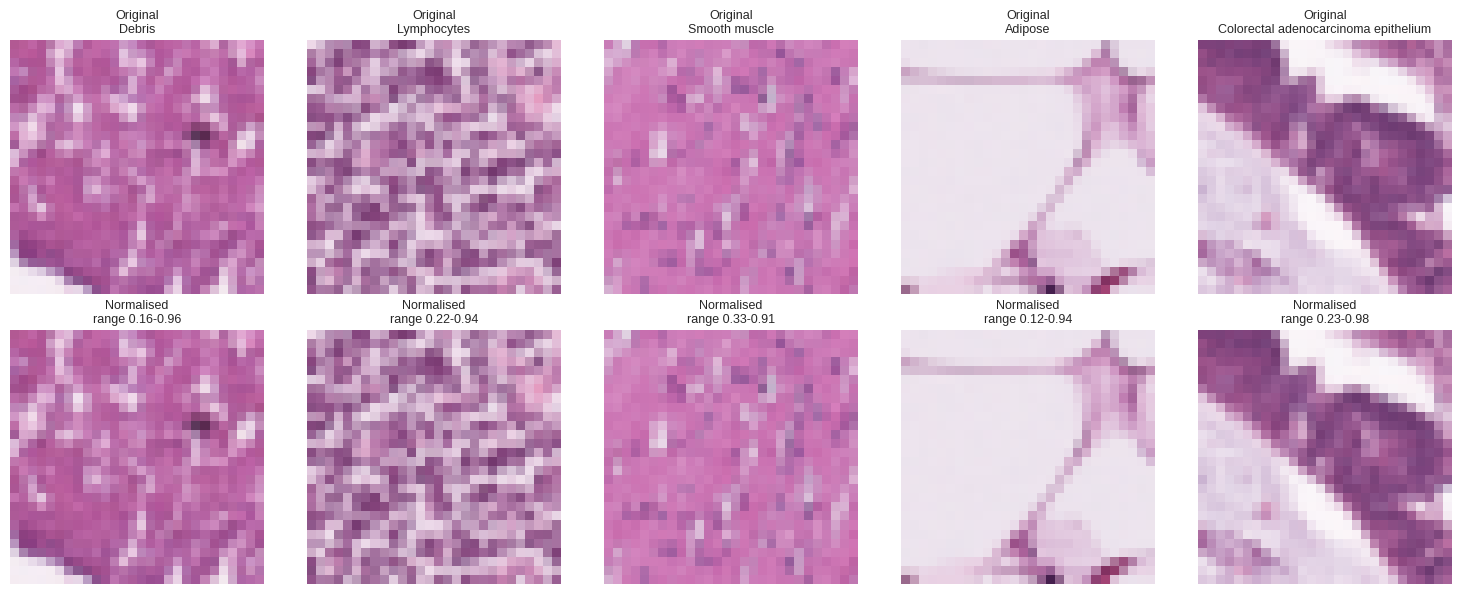

In [11]:
# Compare the original and normalised versions of the same training examples
example_indices = train_indices[:5]
fig, axes = plt.subplots(2, len(example_indices), figsize=(15, 6))

for column, original_index in enumerate(example_indices):
    axes[0, column].imshow(X_train_raw[original_index])
    axes[0, column].set_title(
        f"Original\n{CLASS_NAMES[int(y_train_raw[original_index])]}", fontsize=9
    )
    axes[0, column].axis("off")

    axes[1, column].imshow(X_train_images[column])
    axes[1, column].set_title(
        f"Normalised\nrange {X_train_images[column].min():.2f}-{X_train_images[column].max():.2f}",
        fontsize=9,
    )
    axes[1, column].axis("off")

plt.tight_layout()
plt.show()

### 1.6 Shared evaluation utilities

The functions below give all three models a consistent evaluation procedure. They report accuracy and macro-averaged precision, recall, and F1-score, then display a per-class classification report and confusion matrix. Macro averages give every tissue class equal importance, which is useful when class frequencies differ. Prediction runtime is measured separately from training runtime.

In [12]:
def convert_predictions_to_labels(predictions):
    """Convert class probabilities or class IDs into a one-dimensional label array."""
    predictions = np.asarray(predictions)
    if predictions.ndim == 2:
        return np.argmax(predictions, axis=1)
    return predictions.astype(np.int64).ravel()

def evaluate_predictions(y_true, predictions, model_name, prediction_time=None):
    """Calculate metrics and plot a confusion matrix for one model."""
    y_pred = convert_predictions_to_labels(predictions)
    labels = np.arange(len(CLASS_NAMES))

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro precision": precision_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro recall": recall_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Prediction time (s)": prediction_time,
    }

    display(pd.DataFrame([metrics]).round(4))
    print(
        classification_report(
            y_true,
            y_pred,
            labels=labels,
            target_names=[CLASS_NAMES[label] for label in labels],
            digits=4,
            zero_division=0,
        )
    )

    matrix = confusion_matrix(y_true, y_pred, labels=labels)
    display_labels = [f"{label}: {CLASS_NAMES[label]}" for label in labels]
    figure, axis = plt.subplots(figsize=(11, 9))
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=display_labels,
    ).plot(ax=axis, cmap="Blues", values_format="d", colorbar=False)
    axis.set_title(f"Confusion matrix: {model_name}")
    axis.tick_params(axis="x", rotation=45)
    plt.tight_layout()
    plt.show()

    return metrics, y_pred

def predict_and_evaluate(model, X_evaluation, y_evaluation, model_name, **predict_kwargs):
    """Time model prediction and apply the shared evaluation procedure."""
    start_time = perf_counter()
    predictions = model.predict(X_evaluation, **predict_kwargs)
    prediction_time = perf_counter() - start_time
    return evaluate_predictions(
        y_evaluation,
        predictions,
        model_name=model_name,
        prediction_time=prediction_time,
    )

def plot_training_history(history, model_name):
    """Plot training and validation accuracy and loss from a Keras History object."""
    history_values = history.history
    epochs = np.arange(1, len(history_values["loss"]) + 1)

    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history_values["accuracy"], label="Training")
    axes[0].plot(epochs, history_values["val_accuracy"], label="Validation")
    axes[0].set_title(f"{model_name}: accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()

    axes[1].plot(epochs, history_values["loss"], label="Training")
    axes[1].plot(epochs, history_values["val_loss"], label="Validation")
    axes[1].set_title(f"{model_name}: loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

> **Data-leakage control**
> The validation split is used for model design and hyperparameter selection. The supplied test set must remain untouched until each final model has been fixed and independently trained. Test performance must not be used to revise hyperparameters.
>

## 2. Algorithm design and setup

### Algorithm of choice from first six weeks of course

Random Forest is used as the algorithm of choice from the first six weeks. It is an ensemble of decision trees. Each tree is trained using a bootstrap sample of the training data, and only a random subset of features is considered when selecting a split. The final class is obtained by combining the tree predictions through majority voting.

This is a useful classical baseline for PathMNIST because it can model non-linear relationships between pixel features and is generally more robust to overfitting than a single decision tree. However, flattening the images means that Random Forest does not explicitly exploit the two-dimensional spatial structure of neighbouring pixels, which is an important limitation compared with CNNs.

The shared flattened inputs (`X_train_flat`, `X_validation_flat`, and `X_test_flat`) are used so that the model follows the same group preprocessing and train/validation split as the MLP. Tree splits do not require feature normalisation, but the shared normalised representation remains valid because the linear rescaling preserves the ordering of pixel values.


In [13]:
from sklearn.ensemble import RandomForestClassifier

# A simple baseline is fitted before hyperparameter tuning, as required by the
# assignment's algorithm-design stage.
RF_BASELINE_PARAMS = {
    "n_estimators": 100,
    "max_features": "sqrt",
    "max_depth": None,
}

rf_baseline = RandomForestClassifier(
    **RF_BASELINE_PARAMS,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

baseline_start = perf_counter()
rf_baseline.fit(X_train_flat, y_train_split)
rf_baseline_training_time = perf_counter() - baseline_start

baseline_prediction_start = perf_counter()
rf_baseline_validation_predictions = rf_baseline.predict(X_validation_flat)
rf_baseline_prediction_time = perf_counter() - baseline_prediction_start

rf_baseline_summary = pd.DataFrame(
    [
        {
            "Model": "Random Forest baseline",
            "Validation accuracy": accuracy_score(
                y_validation, rf_baseline_validation_predictions
            ),
            "Validation macro F1": f1_score(
                y_validation,
                rf_baseline_validation_predictions,
                average="macro",
                zero_division=0,
            ),
            "Training time (s)": rf_baseline_training_time,
            "Validation prediction time (s)": rf_baseline_prediction_time,
            **RF_BASELINE_PARAMS,
        }
    ]
)

display(rf_baseline_summary.round(4))


,Model,Validation accuracy,Validation macro F1,Training time (s),Validation prediction time (s),n_estimators,max_features,max_depth
0,Random Forest baseline,0.6306,0.6,95.2805,0.3303,100,sqrt,None


### Fully connected neural network

### Convolutional neural network

## 3. Hyperparameter tuning

### Algorithm of choice from first six weeks of course

A validation-set grid search is used for Random Forest hyperparameter tuning. The supplied test set is not used during this process.

Three hyperparameters are varied:

- `n_estimators`: number of decision trees in the ensemble. More trees can stabilise the majority vote, but increase runtime.
- `max_features`: number of candidate features considered at each split. Random feature selection is a defining part of Random Forest and affects the strength/correlation trade-off between trees.
- `max_depth`: maximum tree depth. Limiting depth can reduce model complexity and runtime, while unrestricted depth allows more detailed partitions.

The grid contains eight combinations so that the search remains computationally manageable on the assignment dataset. Validation accuracy is used to select the final configuration, while macro F1-score and runtime are also recorded for analysis.


In [14]:
from sklearn.model_selection import ParameterGrid

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_features": ["sqrt", "log2"],
    "max_depth": [None, 20],
}

rf_search_results = []
rf_search_start = perf_counter()

for trial_number, params in enumerate(ParameterGrid(rf_param_grid), start=1):
    print(f"Trial {trial_number}/8: {params}")

    model = RandomForestClassifier(
        **params,
        min_samples_leaf=1,
        bootstrap=True,
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

    train_start = perf_counter()
    model.fit(X_train_flat, y_train_split)
    training_time = perf_counter() - train_start

    prediction_start = perf_counter()
    validation_predictions = model.predict(X_validation_flat)
    validation_prediction_time = perf_counter() - prediction_start

    rf_search_results.append(
        {
            **params,
            "validation_accuracy": accuracy_score(
                y_validation, validation_predictions
            ),
            "validation_macro_f1": f1_score(
                y_validation,
                validation_predictions,
                average="macro",
                zero_division=0,
            ),
            "training_time_s": training_time,
            "validation_prediction_time_s": validation_prediction_time,
        }
    )

rf_total_search_time = perf_counter() - rf_search_start

rf_results_df = pd.DataFrame(rf_search_results).sort_values(
    ["validation_accuracy", "validation_macro_f1"],
    ascending=False,
).reset_index(drop=True)

display(rf_results_df.round(4))
print(f"Total Random Forest search time: {rf_total_search_time:.2f} seconds")
print("Best validation configuration:")
display(rf_results_df.head(1))

# Preserve the tuning results for the report and for merging with the group work.
rf_results_df.to_csv(
    "rf_tuning_results.csv",
    index=False,
)


Trial 1/8: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 100}
Trial 2/8: {'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}
Trial 3/8: {'max_depth': None, 'max_features': 'log2', 'n_estimators': 100}
Trial 4/8: {'max_depth': None, 'max_features': 'log2', 'n_estimators': 200}
Trial 5/8: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 100}
Trial 6/8: {'max_depth': 20, 'max_features': 'sqrt', 'n_estimators': 200}
Trial 7/8: {'max_depth': 20, 'max_features': 'log2', 'n_estimators': 100}
Trial 8/8: {'max_depth': 20, 'max_features': 'log2', 'n_estimators': 200}


,max_depth,max_features,n_estimators,validation_accuracy,validation_macro_f1,training_time_s,validation_prediction_time_s
0,NaN,sqrt,200,0.6483,0.6163,188.4385,0.6547
1,20.0,log2,200,0.6420,0.6111,45.6774,1.1043
2,20.0,sqrt,200,0.6412,0.6078,181.2788,0.6378
3,NaN,log2,200,0.6392,0.6063,46.7769,0.8584
4,20.0,sqrt,100,0.6364,0.6059,91.2449,0.2971
5,NaN,sqrt,100,0.6306,0.6000,94.4377,0.3289
6,20.0,log2,100,0.6280,0.5984,21.7543,0.3126
7,NaN,log2,100,0.6272,0.5964,24.3956,0.3430


Total Random Forest search time: 698.65 seconds
Best validation configuration:


,max_depth,max_features,n_estimators,validation_accuracy,validation_macro_f1,training_time_s,validation_prediction_time_s
0,NaN,sqrt,200,0.648281,0.61629,188.438529,0.65473


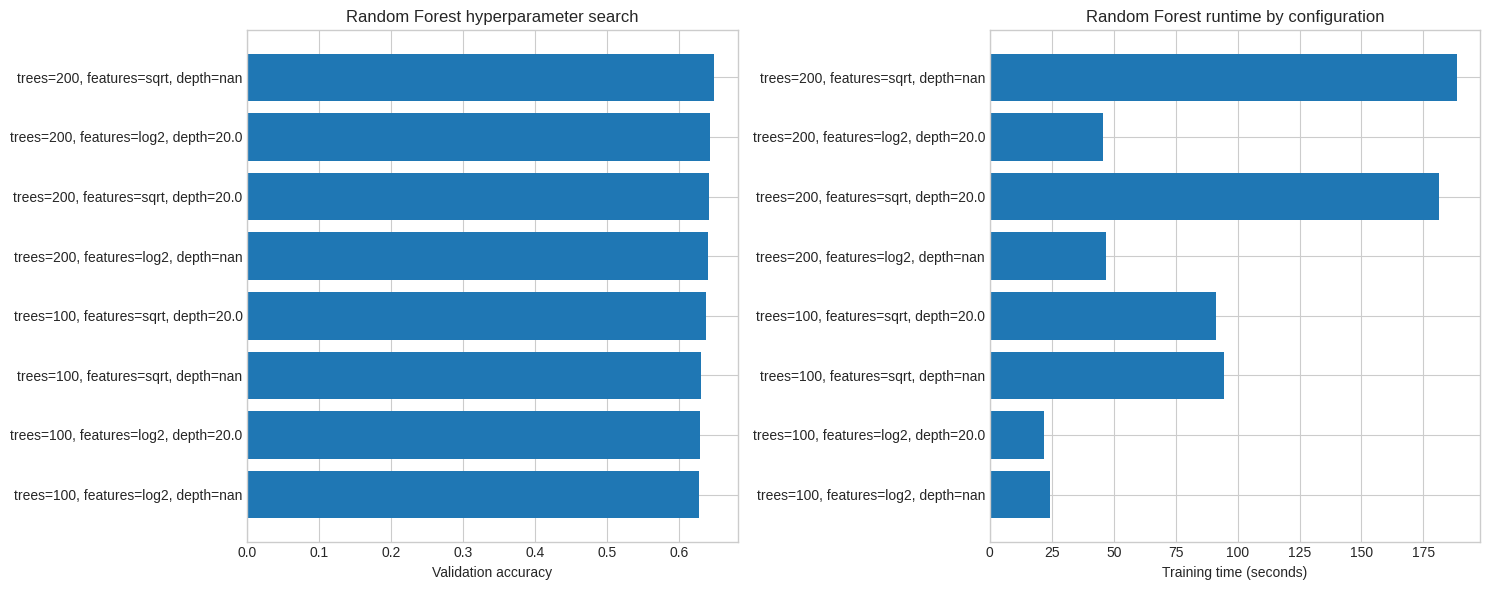

In [15]:
# Visualise the main accuracy/runtime trade-off across all Random Forest trials.
rf_plot_results = rf_results_df.copy()
rf_plot_results["Configuration"] = rf_plot_results.apply(
    lambda row: (
        f"trees={int(row['n_estimators'])}, "
        f"features={row['max_features']}, "
        f"depth={row['max_depth']}"
    ),
    axis=1,
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].barh(
    rf_plot_results["Configuration"],
    rf_plot_results["validation_accuracy"],
)
axes[0].set_xlabel("Validation accuracy")
axes[0].set_title("Random Forest hyperparameter search")
axes[0].invert_yaxis()

axes[1].barh(
    rf_plot_results["Configuration"],
    rf_plot_results["training_time_s"],
)
axes[1].set_xlabel("Training time (seconds)")
axes[1].set_title("Random Forest runtime by configuration")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


After running the search, summarise the main trends here before submission. In particular, report the best validation accuracy and macro F1-score, note whether increasing the number of trees improved validation performance, discuss the effect of `max_features` and `max_depth`, and compare these changes with their runtime costs. Do not invent these observations before the search has been run; use the saved outputs above.


### Fully connected neural network

### Convolutional neural network

## 4. Final models
In this section, please ensure to include cells to train each model with its best hyperparmater combination independently of the hyperparameter tuning cells, i.e. don't rely on the hyperparameter tuning cells having been run.

### Algorithm of choice from first six weeks of course

Random Forest was selected as the classical algorithm from the first six weeks of the course. The final model uses the best hyperparameter combination identified on the validation set. Its parameters are written explicitly below so that this cell can be run independently of the hyperparameter-search cell, as required by the assignment specification.

**Before final submission:** after running Section 3, check the first row of `rf_results_df` and update `RF_FINAL_PARAMS` below if the best configuration differs from the provisional values currently shown.


In [16]:
# Best Random Forest configuration selected using validation performance.
# IMPORTANT: update these explicit values after running Section 3 if another
# configuration has the highest validation accuracy.
RF_FINAL_PARAMS = {
    "n_estimators": 200,
    "max_features": "sqrt",
    "max_depth": None,
}

rf_final = RandomForestClassifier(
    **RF_FINAL_PARAMS,
    min_samples_leaf=1,
    bootstrap=True,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

start_time = perf_counter()
rf_final.fit(X_train_flat, y_train_split)
rf_final_training_time = perf_counter() - start_time

print("Final Random Forest parameters:", RF_FINAL_PARAMS)
print(f"Training time: {rf_final_training_time:.2f} seconds")


Final Random Forest parameters: {'n_estimators': 200, 'max_features': 'sqrt', 'max_depth': None}
Training time: 185.87 seconds


,Model,Accuracy,Macro precision,Macro recall,Macro F1,Prediction time (s)
0,Random Forest,0.6556,0.658,0.635,0.6204,1.1888


                                      precision    recall  f1-score   support

                             Adipose     0.8188    0.9782    0.8914       873
                          Background     0.9885    0.8998    0.9420       858
                              Debris     0.6580    0.3181    0.4289       877
                         Lymphocytes     0.7587    0.7604    0.7596       914
                               Mucus     0.5234    0.6676    0.5868       737
                       Smooth muscle     0.6363    0.7360    0.6825      1072
                 Normal colon mucosa     0.5200    0.1144    0.1875       682
            Cancer-associated stroma     0.4981    0.4723    0.4848       813
Colorectal adenocarcinoma epithelium     0.5199    0.7683    0.6201      1174

                            accuracy                         0.6556      8000
                           macro avg     0.6580    0.6350    0.6204      8000
                        weighted avg     0.6589    0.6556    0

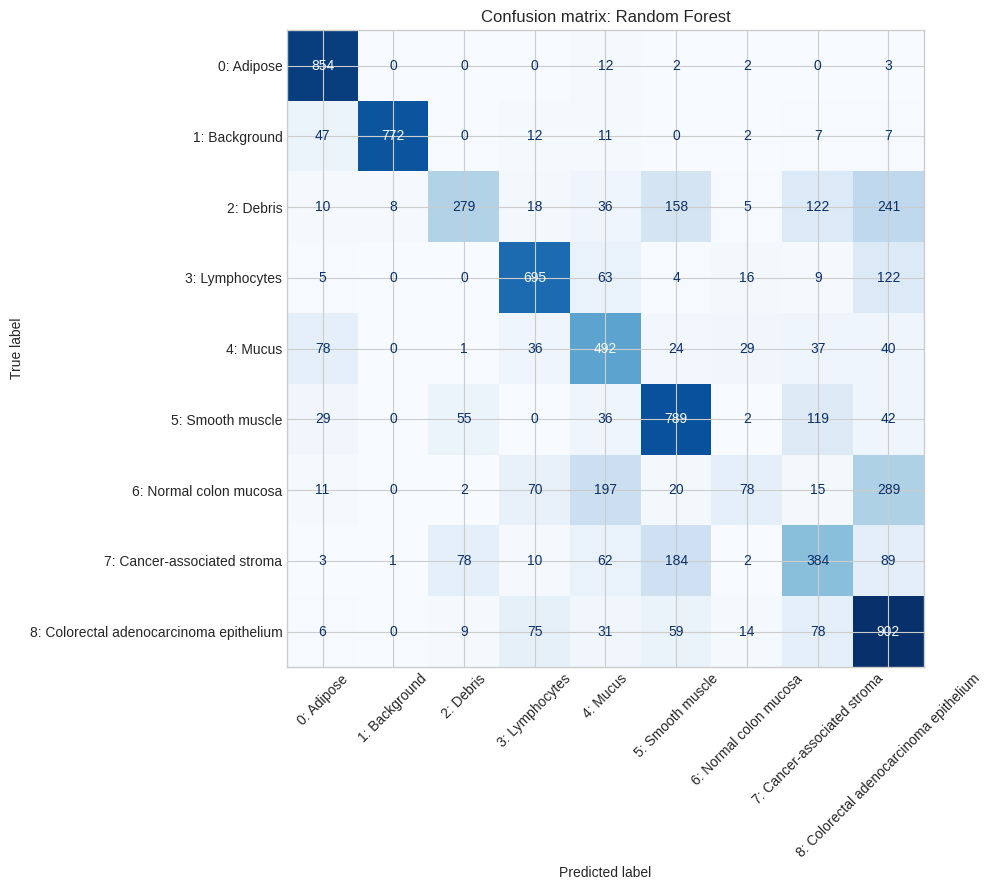

,Model,Accuracy,Macro precision,Macro recall,Macro F1,Prediction time (s),Training time (s),n_estimators,max_features,max_depth
0,Random Forest,0.6556,0.658,0.635,0.6204,1.1888,185.8732,200,sqrt,None


In [17]:
rf_metrics, rf_test_predictions = predict_and_evaluate(
    model=rf_final,
    X_evaluation=X_test_flat,
    y_evaluation=y_test_final,
    model_name="Random Forest",
)

rf_metrics["Training time (s)"] = rf_final_training_time
rf_metrics["n_estimators"] = RF_FINAL_PARAMS["n_estimators"]
rf_metrics["max_features"] = RF_FINAL_PARAMS["max_features"]
rf_metrics["max_depth"] = str(RF_FINAL_PARAMS["max_depth"])

rf_final_results_df = pd.DataFrame([rf_metrics])
display(rf_final_results_df.round(4))

# Save final metrics so they can be merged into the group comparison table.
rf_final_results_df.to_csv(
    "rf_final_results.csv",
    index=False,
)


Use the output above for the final report comparison. Report at least test accuracy, macro precision, macro recall, macro F1-score, training time, and prediction time. Also comment on the confusion matrix: identify classes that Random Forest handles relatively well or poorly, and compare these patterns with MLP and CNN once the group results are merged.


### Fully connected neural network

### Convolutional neural network

## 5. AI Acknowledgement
Include acknowledgement of AI usage here.

**AI acknowledgement draft (edit to match the group's actual use):** Generative AI was used to assist with code structure, debugging, and explanation of the Random Forest implementation. All generated code and explanations were reviewed by the group, and the final model outputs and reported results were produced by running the submitted notebook on the assignment dataset.
